# Liquid Level Detection (Roboflow SAM2)

> Real-world images of transparent containers for liquid-region detection (Roboflow export; resized to 640×640).

**GT available (per image):**
- One or more liquid-region segmentations stored as RLE masks in per-image JSON (COCO-style `segmentation.counts` + `size`)
- Bounding boxes per annotation (`bbox`) and area (`area`)

In [1]:
from __future__ import annotations

import json
from collections import Counter
from dataclasses import dataclass
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

try:
    from pycocotools import mask as mask_utils
except Exception as e:
    raise ImportError("Missing dependency: pycocotools. Install it with: pip install pycocotools") from e

ROOT = Path("..") / "data" / "liquid level detection.v1i.sam2"
SPLITS = {"train": ROOT / "train", "valid": ROOT / "valid", "test": ROOT / "test"}

assert ROOT.exists(), f"Dataset root not found: {ROOT}"
for name, p in SPLITS.items():
    assert p.exists(), f"Split folder not found: {p}"

print(f"Dataset root: {ROOT}")
print("Splits:", {k: str(v) for k, v in SPLITS.items()})

Dataset root: ../data/liquid level detection.v1i.sam2
Splits: {'train': '../data/liquid level detection.v1i.sam2/train', 'valid': '../data/liquid level detection.v1i.sam2/valid', 'test': '../data/liquid level detection.v1i.sam2/test'}


## Layout and file pairing

Roboflow exports each split as flat files:

- `*.jpg` images
- One sidecar `*.json` per image with keys `image` and `annotations`
- Each annotation includes `bbox`, `area`, and RLE `segmentation` with `counts` + `size`

In [2]:
def list_image_json_pairs(split_dir: Path) -> list[tuple[Path, Path]]:
    images = sorted(split_dir.glob("*.jpg"))
    pairs: list[tuple[Path, Path]] = []
    missing = 0
    for img in images:
        js = img.with_suffix(".json")
        if js.exists():
            pairs.append((img, js))
        else:
            missing += 1
    if missing:
        print(f"WARNING: {split_dir.name}: missing {missing} JSON sidecars")
    return pairs

pairs_by_split = {name: list_image_json_pairs(path) for name, path in SPLITS.items()}

total_pairs = sum(len(v) for v in pairs_by_split.values())
print("Image/JSON pairs per split:")
for name, pairs in pairs_by_split.items():
    print(f"- {name:<5} {len(pairs):>4}")
print(f"Total paired images: {total_pairs}")

# Quick sanity check on image resolution
sample_img = pairs_by_split["train"][0][0]
w, h = Image.open(sample_img).size
print(f"Sample image size: {sample_img.name} -> {w}×{h}")

Image/JSON pairs per split:
- train  609
- valid   60
- test    28
Total paired images: 697
Sample image size: IMG_20250401_145535_jpg.rf.3629fa64001414570e48741626e48736.jpg -> 640×640


## Annotation schema (per-image JSON)

Each JSON is a single COCO-like record:

- `image`: metadata (`file_name`, `height`, `width`, etc.)
- `annotations`: list of instances
  - `bbox`: `[x, y, w, h]`
  - `area`: mask area (float)
  - `segmentation`: RLE with `counts` and `size`

Note: these masks are decodable with `pycocotools`.

In [3]:
img_path, json_path = pairs_by_split["train"][0]
record = json.loads(json_path.read_text())

print("Top-level keys:", list(record.keys()))
print("Image keys:", list(record["image"].keys()))
print("#annotations:", len(record.get("annotations", [])))

ann0 = record["annotations"][0]
print("Annotation keys:", list(ann0.keys()))
print("bbox example:", ann0["bbox"])
print("area example:", ann0["area"])
print("segmentation keys:", list(ann0["segmentation"].keys()))
print("segmentation.size:", ann0["segmentation"]["size"])

Top-level keys: ['image', 'annotations']
Image keys: ['image_id', 'license', 'file_name', 'height', 'width', 'date_captured', 'extra']
#annotations: 3
Annotation keys: ['id', 'bbox', 'area', 'segmentation']
bbox example: [292, 145, 217.33333299999998, 237.666667]
area example: 51652.8888821111
segmentation keys: ['counts', 'size']
segmentation.size: [640, 640]


## Dataset statistics

We’ll compute basic per-split summaries and a couple quick plots:

- number of instances per image
- instance area distribution (from JSON and from decoded masks)
- bbox width/height distribution

In [4]:
@dataclass(frozen=True)
class InstanceStats:
    split: str
    image_name: str
    ann_id: int
    bbox_w: float
    bbox_h: float
    area_field: float
    area_decoded: int


def decode_rle_mask(segmentation: dict[str, Any]) -> np.ndarray:
    # pycocotools expects `counts` as bytes.
    rle = {"size": segmentation["size"], "counts": segmentation["counts"].encode("utf-8")}
    m = mask_utils.decode(rle)
    # mask_utils.decode can return (H,W,1) depending on input; normalize to (H,W).
    if m.ndim == 3:
        m = m[..., 0]
    return m.astype(bool)


def collect_stats(split: str, pairs: list[tuple[Path, Path]], max_images: int | None = None):
    rows: list[InstanceStats] = []
    per_image_counts: list[int] = []
    sampled = pairs if max_images is None else pairs[:max_images]
    for img_path, json_path in sampled:
        rec = json.loads(json_path.read_text())
        anns = rec.get("annotations", [])
        per_image_counts.append(len(anns))
        for ann in anns:
            bbox = ann["bbox"]
            segm = ann["segmentation"]
            mask = decode_rle_mask(segm)
            rows.append(
                InstanceStats(
                    split=split,
                    image_name=img_path.name,
                    ann_id=int(ann.get("id", -1)),
                    bbox_w=float(bbox[2]),
                    bbox_h=float(bbox[3]),
                    area_field=float(ann.get("area", float("nan"))),
                    area_decoded=int(mask.sum()),
                )
            )
    return per_image_counts, rows

per_image_counts_by_split: dict[str, list[int]] = {}
instance_rows: list[InstanceStats] = []

for split, pairs in pairs_by_split.items():
    counts, rows = collect_stats(split, pairs)
    per_image_counts_by_split[split] = counts
    instance_rows.extend(rows)

print("Per-split instance counts:")
for split, counts in per_image_counts_by_split.items():
    print(f"- {split:<5} images={len(counts):>4}  instances={sum(counts):>5}  mean_instances_per_image={np.mean(counts):.2f}")

# Basic correlation: area field vs decoded area
areas_field = np.array([r.area_field for r in instance_rows], dtype=float)
areas_dec = np.array([r.area_decoded for r in instance_rows], dtype=float)
valid = np.isfinite(areas_field)
corr = np.corrcoef(areas_field[valid], areas_dec[valid])[0, 1] if valid.sum() > 2 else float('nan')
print(f"Area(field) vs Area(decoded) correlation: {corr:.3f}")

Per-split instance counts:
- train images= 609  instances= 1755  mean_instances_per_image=2.88
- valid images=  60  instances=  171  mean_instances_per_image=2.85
- test  images=  28  instances=   77  mean_instances_per_image=2.75
Area(field) vs Area(decoded) correlation: 0.995


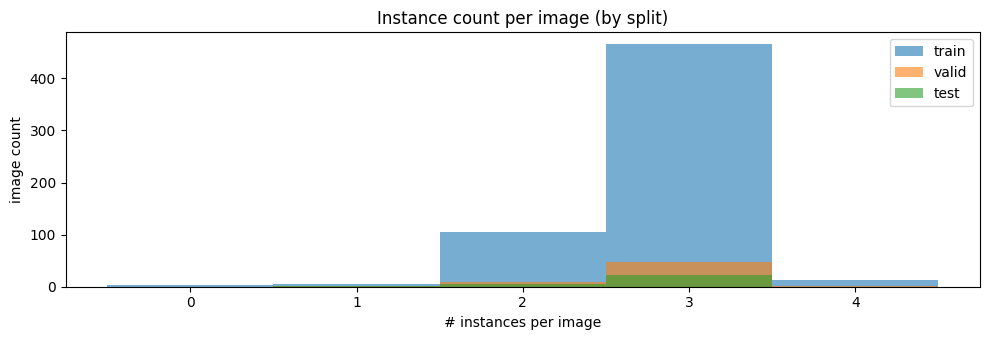

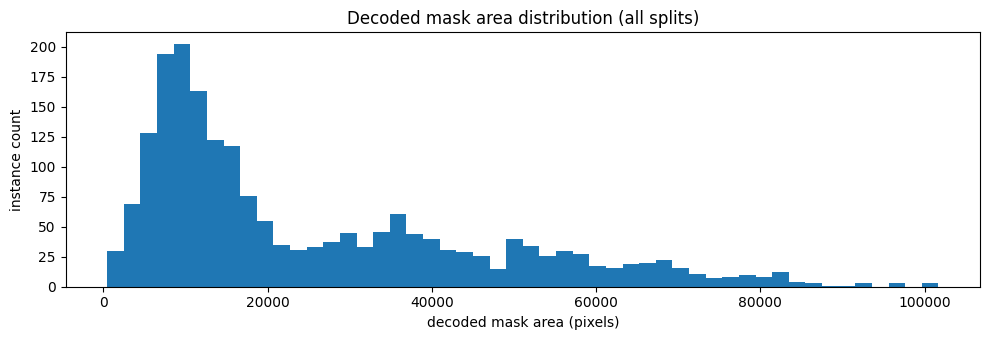

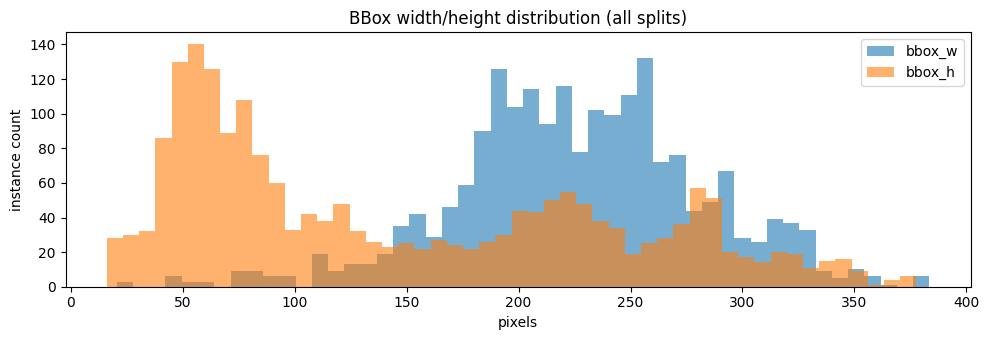

In [5]:
# Plots
plt.figure(figsize=(10, 3.5))
bins = np.arange(0, 6) - 0.5
for split, counts in per_image_counts_by_split.items():
    plt.hist(counts, bins=bins, alpha=0.6, label=split)
plt.xticks(range(0, 5))
plt.xlabel('# instances per image')
plt.ylabel('image count')
plt.title('Instance count per image (by split)')
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 3.5))
areas = np.array([r.area_decoded for r in instance_rows], dtype=float)
plt.hist(np.clip(areas, 0, 640 * 640), bins=50)
plt.xlabel('decoded mask area (pixels)')
plt.ylabel('instance count')
plt.title('Decoded mask area distribution (all splits)')
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 3.5))
bbox_w = np.array([r.bbox_w for r in instance_rows], dtype=float)
bbox_h = np.array([r.bbox_h for r in instance_rows], dtype=float)
plt.hist(bbox_w, bins=50, alpha=0.6, label='bbox_w')
plt.hist(bbox_h, bins=50, alpha=0.6, label='bbox_h')
plt.xlabel('pixels')
plt.ylabel('instance count')
plt.title('BBox width/height distribution (all splits)')
plt.legend()
plt.tight_layout()
plt.show()

## Visualization helpers

The helper below renders one image with:

- multi-instance mask overlay (distinct colors)
- optional bounding boxes
- a short title (filename + instance count)

In [6]:
def load_rgb_image(path: Path) -> np.ndarray:
    img = Image.open(path).convert('RGB')
    return np.asarray(img)


def load_record(json_path: Path) -> dict[str, Any]:
    return json.loads(json_path.read_text())


def decode_instance_masks(annotations: list[dict[str, Any]]) -> list[np.ndarray]:
    masks: list[np.ndarray] = []
    for ann in annotations:
        masks.append(decode_rle_mask(ann['segmentation']))
    return masks


def overlay_masks(rgb: np.ndarray, masks: list[np.ndarray], alpha: float = 0.35) -> np.ndarray:
    out = rgb.astype(np.float32).copy()
    if not masks:
        return rgb
    colors = plt.get_cmap('tab10').colors
    for i, m in enumerate(masks):
        color = np.array(colors[i % len(colors)], dtype=np.float32) * 255.0
        m3 = m[..., None]
        out = np.where(m3, (1 - alpha) * out + alpha * color, out)
    return np.clip(out, 0, 255).astype(np.uint8)


def draw_bboxes(ax, annotations: list[dict[str, Any]], color: str = 'lime'):
    import matplotlib.patches as patches

    for ann in annotations:
        x, y, w, h = ann['bbox']
        rect = patches.Rectangle((x, y), w, h, linewidth=2, edgecolor=color, facecolor='none')
        ax.add_patch(rect)


def render_example(ax, img_path: Path, json_path: Path, show_bboxes: bool = True):
    rgb = load_rgb_image(img_path)
    rec = load_record(json_path)
    anns = rec.get('annotations', [])
    masks = decode_instance_masks(anns)
    vis = overlay_masks(rgb, masks)

    ax.imshow(vis)
    if show_bboxes:
        draw_bboxes(ax, anns)
    ax.set_title(f"{img_path.name}  (n={len(anns)})", fontsize=7)
    ax.axis('off')


def show_random_grid(split: str, n: int = 24, seed: int = 0, cols: int = 6, show_bboxes: bool = True):
    pairs = pairs_by_split[split]
    rng = np.random.default_rng(seed)
    n = min(n, len(pairs))
    idx = rng.choice(len(pairs), size=n, replace=False)
    chosen = [pairs[i] for i in idx]

    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 3.0, rows * 3.0))
    axes = np.array(axes).reshape(-1)
    for ax, (img_path, json_path) in zip(axes, chosen):
        render_example(ax, img_path, json_path, show_bboxes=show_bboxes)
    for ax in axes[len(chosen):]:
        ax.axis('off')
    fig.suptitle(f"Random examples — {split} (n={n}, seed={seed})")
    plt.tight_layout()
    plt.show()

## Many random qualitative examples

These cells render **lots** of random images with multi-instance overlays.

Tip: tweak `n`, `cols`, and `seed` to sample different subsets.

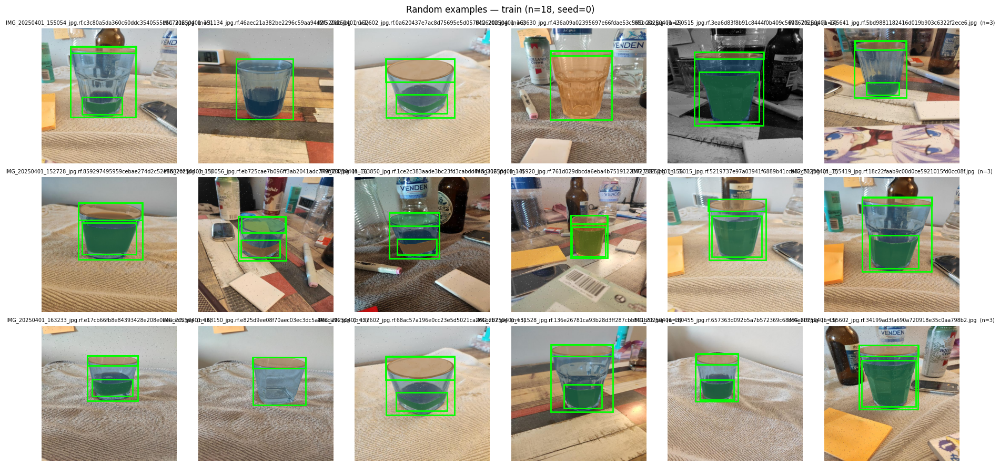

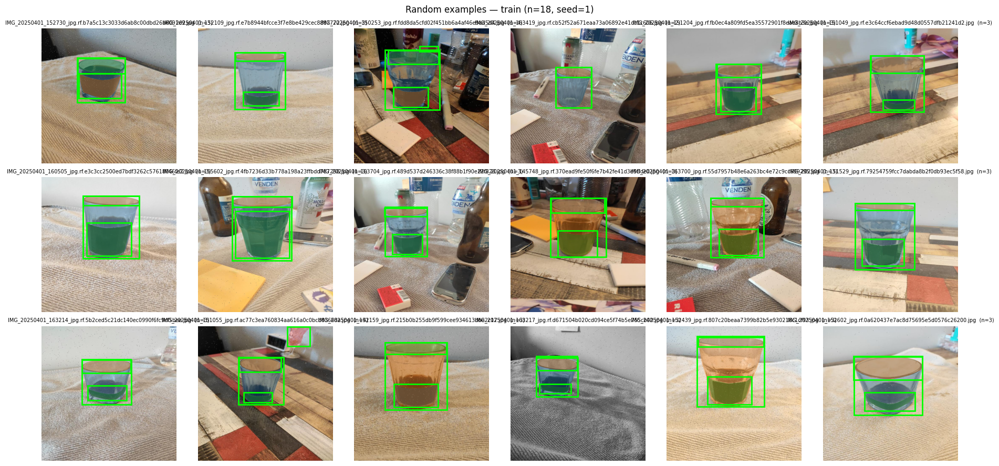

In [7]:
show_random_grid('train', n=18, seed=0, cols=6, show_bboxes=True)
show_random_grid('train', n=18, seed=1, cols=6, show_bboxes=True)

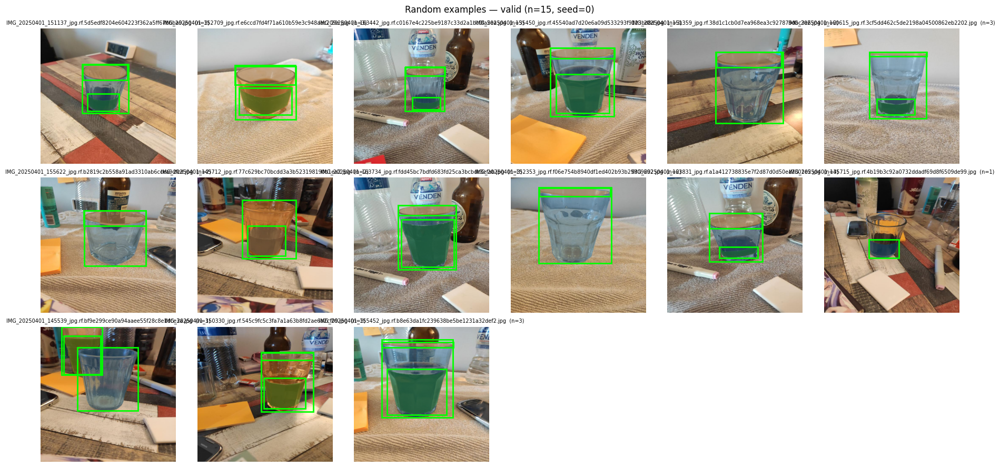

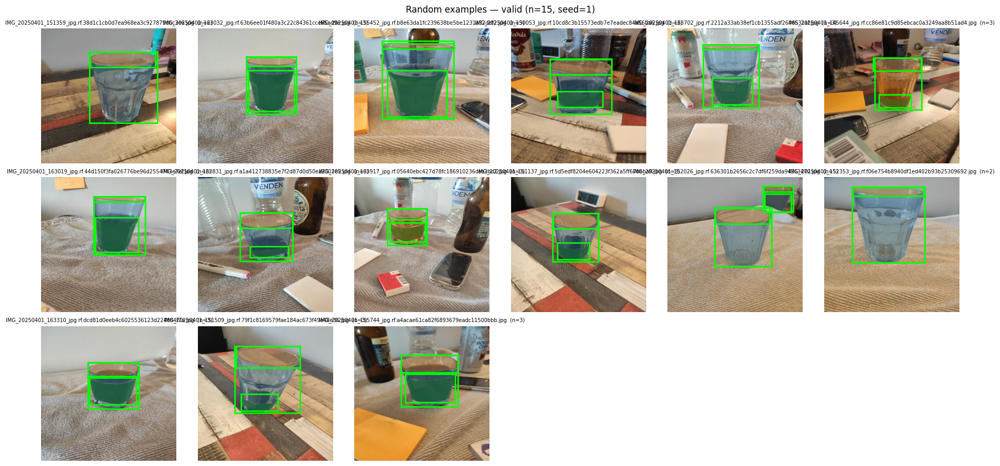

In [8]:
show_random_grid('valid', n=15, seed=0, cols=6, show_bboxes=True)
show_random_grid('valid', n=15, seed=1, cols=6, show_bboxes=True)

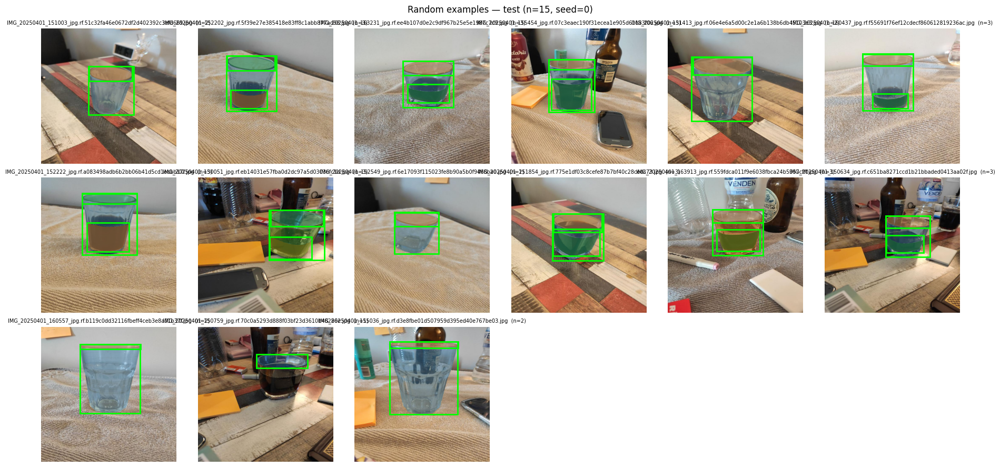

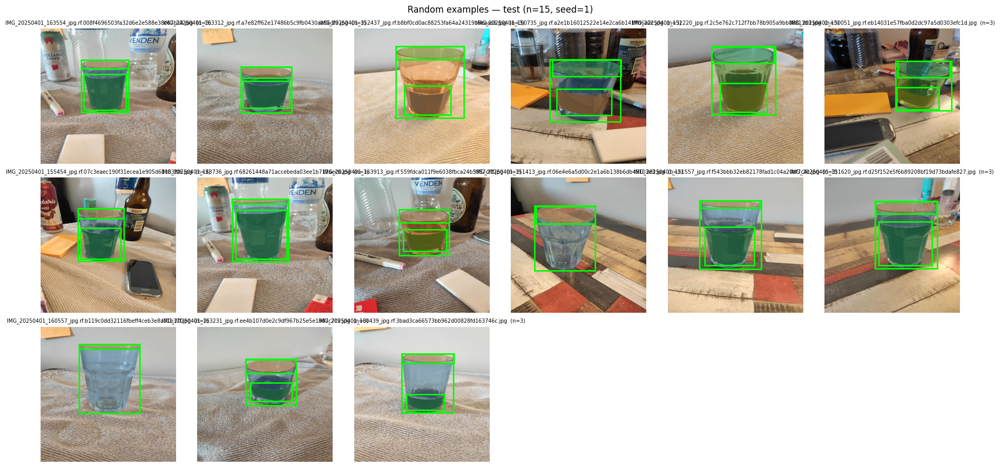

In [9]:
show_random_grid('test', n=15, seed=0, cols=6, show_bboxes=True)
show_random_grid('test', n=15, seed=1, cols=6, show_bboxes=True)

## Deep dive on a single random image

This shows the original RGB, the combined overlay, and each instance mask separately.

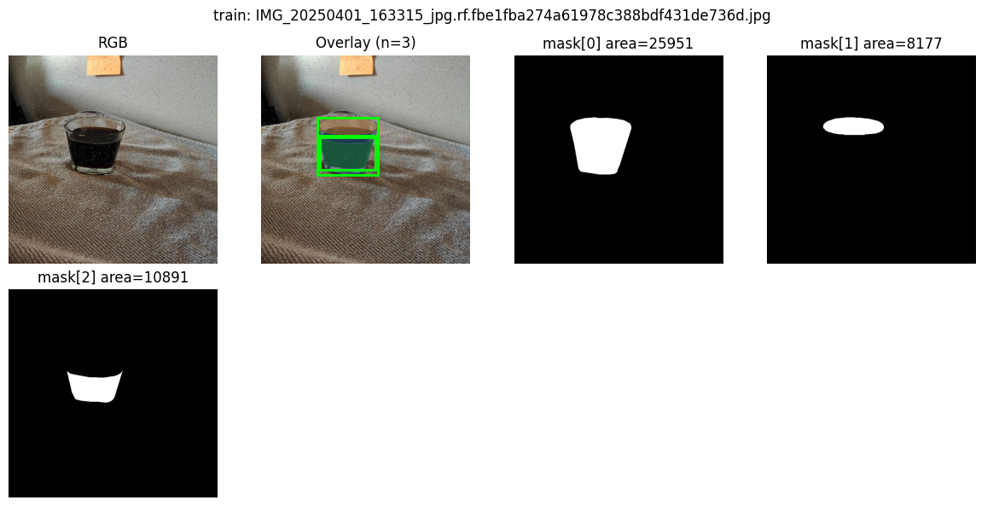

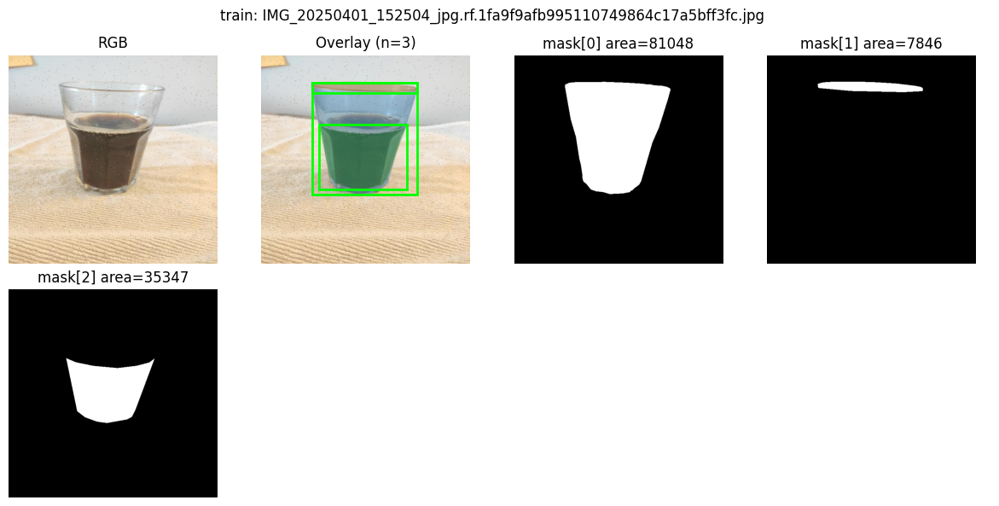

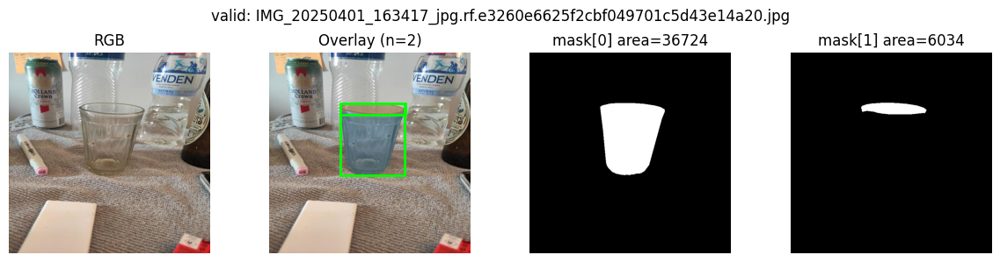

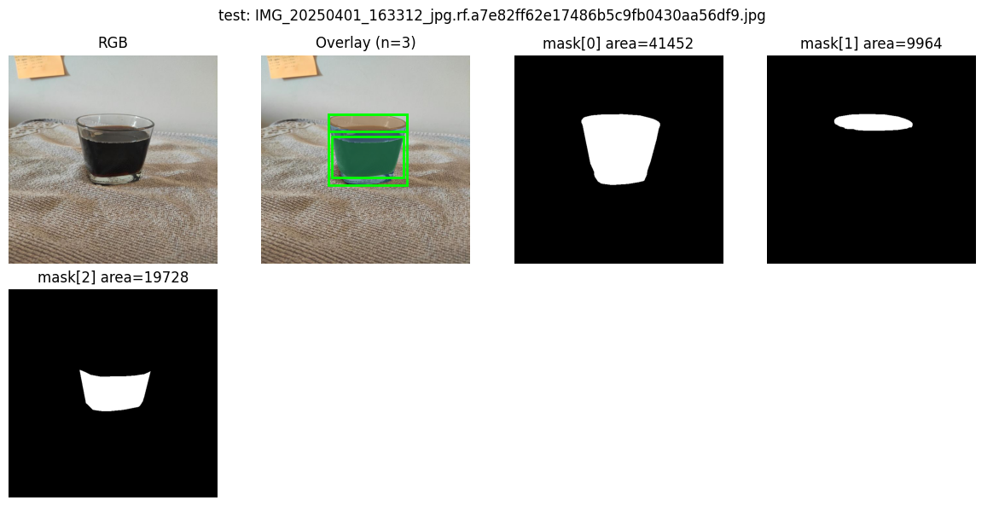

In [10]:
def show_single_example(split: str, seed: int = 0):
    rng = np.random.default_rng(seed)
    img_path, json_path = pairs_by_split[split][int(rng.integers(0, len(pairs_by_split[split])))]
    rgb = load_rgb_image(img_path)
    rec = load_record(json_path)
    anns = rec.get('annotations', [])
    masks = decode_instance_masks(anns)
    overlay = overlay_masks(rgb, masks)

    n = len(masks)
    cols = 4
    rows = int(np.ceil((2 + n) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 3.0, rows * 3.0))
    axes = np.array(axes).reshape(-1)

    axes[0].imshow(rgb)
    axes[0].set_title('RGB')
    axes[0].axis('off')

    axes[1].imshow(overlay)
    draw_bboxes(axes[1], anns)
    axes[1].set_title(f'Overlay (n={n})')
    axes[1].axis('off')

    for i, m in enumerate(masks):
        ax = axes[2 + i]
        ax.imshow(m, cmap='gray')
        ax.set_title(f'mask[{i}] area={int(m.sum())}')
        ax.axis('off')

    for ax in axes[2 + n:]:
        ax.axis('off')

    fig.suptitle(f'{split}: {img_path.name}')
    plt.tight_layout()
    plt.show()

show_single_example('train', seed=0)
show_single_example('train', seed=1)
show_single_example('valid', seed=0)
show_single_example('test', seed=0)